# Eigenvalues and Eigenvectors

In [35]:
import numpy as np
import scipy.linalg as sla
import numpy.linalg as la
import random
import matplotlib.pyplot as plt
%matplotlib inline

# I Eigenvalue problem

## Eigenvalue problem

Let $A$ be an $n\times n$ matrix:
$x \neq 0$ is an eigenvector of $A$ if there exists a scalar $\lambda$ such that
$$
A x = \lambda x
$$
where $\lambda$ is called an eigenvalue.  
If $x$ is an eigenvector, then $\alpha x$ is also an eigenvector. Therefore, we will usually seek for normalized eigenvectors, so that
$$
\|x\|_p = 1
$$
Note: When using Python, numpy.linalg.eig will normalize using $p=2$ norm

## How do we find eigenvalues?

Linear algebra approach:  
$$
A x = \lambda x
\\
(A - \lambda I) x = \bf{0}
$$
Therefore the matrix $(A - \lambda I)$ is singular $\Rightarrow \boxed{det(A - \lambda I) = 0}$  
$p(\lambda) = det(A - \lambda I)$ is the characteristic polynomial of degree $n$.  

In most cases, there is no analytical formula for the eigenvalues of a matrix (Abel proved in 1824 that there can be no formula for the roots of a polynomial of degree 5 or higher) $\Rightarrow$ Approximate the
eigenvalues numerically!

<details>
<summary>Example</summary>

$$
A = 
\begin{pmatrix}
2 & 1\\
4 & 2
\end{pmatrix}
\\
\Rightarrow
p(\lambda) = det(A - \lambda I) = (2 - \lambda)(2 - \lambda) - 4 = \lambda^2 - 4\lambda = \lambda(\lambda - 4)
\\
\Rightarrow
\lambda _1 = 0, \lambda _2 = 4
$$

</details>

In [36]:
A = np.array([
    [2, 1],
    [4, 2]
])
eigenvalues, eigenvectors = la.eig(A)
print(eigenvalues)
print(eigenvectors) # the eigenvectors give by la have norms=1 by default

[4.+0.j 0.+0.j]
[[ 0.4472136 +0.j -0.4472136 +0.j]
 [ 0.89442719+0.j  0.89442719+0.j]]


# II Diagonalizable Matrix

A $n \times n$ matrix $A$ with $n$ linearly independent eigenvectors $\bf{u}$ is said to be diagonalizable.

$$
\begin{aligned}
A \bf{u_1} = \lambda \bf{u_1} \\
A \bf{u_2} = \lambda \bf{u_2} \\
\vdots \\
A \bf{u_n} = \lambda \bf{u_n} \\
\end{aligned}
$$

$$
\Rightarrow 
\begin{bmatrix} A \end{bmatrix}
\begin{bmatrix}
| & | & & | \\
\mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
=
\begin{bmatrix}
| & | & & | \\
\lambda \mathbf{u}_1 & \lambda \mathbf{u}_2 & \cdots & \lambda \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
$$

$$
=
\begin{bmatrix}
| & | & & | \\
\mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_n \\
| & | & & |
\end{bmatrix}
\begin{bmatrix}
\lambda_1    \\
  & \lambda_2   \\
 & & \ddots &  \\
  &   &  & \lambda_n
\end{bmatrix}
$$

If $A$ has $n$ linearly independent eigenvectors, then $U$ is full rank. Therefore, we can have
$$
A = UDU^{-1}
$$

<details>
<summary>Example</summary>

$$
A = 
\begin{pmatrix}
2 & 1\\
4 & 2
\end{pmatrix}
\\
\lambda _1 = 0, \lambda _2 = 4
x_1 = \begin{pmatrix}0.447\\0.894\end{pmatrix}, x_2 = \begin{pmatrix}-0.447\\0.894\end{pmatrix}
$$
then
$$
U = 
\begin{pmatrix}
0.447 & -0.447\\
0.894 & 0.894
\end{pmatrix} \\
D = 
\begin{pmatrix}
4 & 0\\
0 & 0
\end{pmatrix}
$$

</details>

In [37]:
eigenvalues, U = la.eig(A)

D = np.diag(eigenvalues)
U_inv = np.linalg.inv(U)

print("U =\n", U)
print("D =\n", D)
print("U^-1 =\n", U_inv)

print(np.allclose(A, U @ D @ U_inv))  # True

U =
 [[ 0.4472136 +0.j -0.4472136 +0.j]
 [ 0.89442719+0.j  0.89442719+0.j]]
D =
 [[4.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
U^-1 =
 [[ 1.11803399+0.j  0.55901699+0.j]
 [-1.11803399+0.j  0.55901699+0.j]]
True


1) If a $n \times n$ matrix $A$ has $n$ linearly independent eigenvectors $\bf{x}$ then $A$ is
diagonalizable, i.e., $A = UDU^{-1}$  
where the columns of $U$ are the linearly independent normalized eigenvectors $\bf{x}$ of $A$ (which guarantees that $U^{-1}$ exists) and $D$ is a diagonal
matrix with the eigenvalues of $A$.
2) If a $n \times n$ matrix $A$ has less then $n$ linearly independent eigenvectors, the
matrix is called **defective** (and therefore not diagonalizable).
3) If a $n \times n$ **symmetric** matrix $A$ has $n$ distinct eigenvalues then $A$ is
diagonalizable.

Proof:

Suppose $\lambda, \mathbf{u}$ and $\mu, \mathbf{v}$ are eigenpairs of $A$ with $\lambda \ne \mu$.



Since $A$ is symmetric, $A^T=A$. Then
$$
\lambda \mathbf{u}^T\mathbf{v}
=(A\mathbf{u})^T\mathbf{v}
=\mathbf{u}^TA^T\mathbf{v}
=\mathbf{u}^TA\mathbf{v}
=\mu\mathbf{u}^T\mathbf{v}.
$$

Therefore,
$$
(\lambda-\mu)\mathbf{u}^T\mathbf{v}=0.
$$

Since $\lambda\ne\mu$, we have
$$
\mathbf{u}^T\mathbf{v}=0.
$$

Thus, eigenvectors corresponding to distinct eigenvalues are orthogonal.

Since $A$ has $n$ distinct eigenvalues, it has $n$ linearly independent eigenvectors. Therefore, $A$ is diagonalizable.

Some things to remember about eigenvalues:  
• Eigenvalues can have zero value  
• Eigenvalues can be negative  
• Eigenvalues can be real or complex numbers  
• A $n \times n$ real matrix can have complex eigenvalues  
• The eigenvalues of a $n \times n$ matrix are not necessarily unique. In fact, we can define the multiplicity of an eigenvalue.  
• If a $n \times n$ matrix has $n$ linearly independent eigenvectors, then the matrix is diagonalizable  

# III Obtaining eigenvalues and eigenvectors numerically

## Power iteration

Assume that $A$ is diagonalizable (i.e., it has $n$ linearly independent eigenvectors $\bf{u}$). We can propose a vector $\bf{x}$ which is a linear combination of these eigenvectors:  
$$
\begin{aligned}
\bf{x} 
= 
\alpha _1 \bf{u}_1 + \alpha _2 \bf{u}_2 + \cdots + \alpha _n \bf{u}_n  
\\
\Rightarrow
\bf{A} \bf{x} 
= 
\bf{A} \alpha _1 \bf{u}_1 + \bf{A} \alpha _2 \bf{u}_2 + \cdots + \bf{A} \alpha _n \bf{u}_n  \\
= 
\alpha _1 \lambda _1 \bf{u}_1 + \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \alpha _n \lambda _n \bf{u}_n  \\
\end{aligned}
$$
Assume: $|\lambda _1| > |\lambda _2| \geq |\lambda _3| \geq \cdots \geq |\lambda _n|$


Our goal is to find an eigenvector $\bf{u_i}$ of $A$. We will use an iterative process, where we start with an initial vector, where here we assume that it can be written as a linear combination of the eigenvectors of $A$.
$$
\bf{x}_0 
= 
\alpha _1 \bf{u}_1 + \alpha _2 \bf{u}_2 + \cdots + \alpha _n \bf{u}_n  
$$

$$
\Rightarrow
\bf{A} \bf{x}_0
= 
\alpha _1 \lambda _1 \bf{u}_1 + \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \alpha _n \lambda _n \bf{u}_n
=
\bf{x}_1
$$

$$
\Rightarrow
\bf{A} \bf{x}_1
= 
\bf{A} \alpha _1 \lambda _1 \bf{u}_1 + \bf{A} \alpha _2 \lambda _2 \bf{u}_2 + \cdots + \bf{A} \alpha _n \lambda _n \bf{u}_n
=
\alpha _1 \lambda _1 ^2 \bf{u}_1 + \alpha _2 \lambda _2 ^2 \bf{u}_2 + \cdots + \alpha _n \lambda _n ^2 \bf{u}_n
=
\bf{x}_2
$$

$$
\bf{A} \bf{x}_2
=
\alpha _1 \lambda _1 ^3 \bf{u}_1 + \alpha _2 \lambda _2 ^3 \bf{u}_2 + \cdots + \alpha _n \lambda _n ^3 \bf{u}_n
=
\bf{x}_3
$$

$$
\cdots \\
\bf{A} \bf{x}_{k-1}
=
\alpha _1 \lambda _1 ^k \bf{u}_1 + \alpha _2 \lambda _2 ^k \bf{u}_2 + \cdots + \alpha _n \lambda _n ^k \bf{u}_n
=
\bf{x}_k
$$

or
$$
\bf{x}_k
=
(\lambda _1)^k [\alpha _1 \bf{u}_1 + \alpha _2 \frac{\lambda _2}{{\lambda _1}} ^k \bf{u}_2 + \cdots + \alpha _n \frac{\lambda _n}{{\lambda _1}} ^k \bf{u}_n]
$$
Assume that $\alpha _1 \neq 0$, the term $\alpha _1 \bf{u}_1$ dominates the others when $k$ is
very large.  
Since $|\lambda _1| > |\lambda _2|$, we have $(\frac{\lambda _2}{\lambda _1})^k \ll 1$ when $k$ is
very large.  
Hence, as $k$ increases, $\bf{x}_k$ converges to a multiple of the first eigenvector $\bf{u}_1$, i.e., 
$$
k \to \infty, \bf{x}_k \to (\lambda _1)^k \alpha _1 \bf{u}_1
$$

## Try it in python

We want to prepare a matrix with deliberately chosen eigenvalues. Let's use diagonalization to write the matrix $\mathbf{A}$:

$$ \mathbf{A} = \mathbf{U D U}^{-1} $$

where we set ${\bf D}$ to be a known matrix with the pre-defined eigenvalues:

```python
D = np.diag([lambda1, lambda2, ..., lambdan])
```

We need to generate a matrix $\mathbf{U}$ that has an inverse. Orthogonal matrices are a great option here, since $\mathbf{U}^{-1} = \mathbf{U}^T$. We use QR decomposition to get an orthogonal matrix (you don't need to understand this method).

In [38]:
n = 4
X = np.random.rand(n,n)
U,_ = sla.qr(X)

D = np.diag([6,2,4,7])

In [39]:
print(U)

[[-0.19260338  0.78117384  0.47282927 -0.35931025]
 [-0.73089464 -0.18189106  0.39976109  0.52239807]
 [-0.45065315 -0.45123112 -0.02314807 -0.76991323]
 [-0.47498284  0.39124615 -0.78491256  0.07231892]]


Now we can use diagonalization to write $\mathbf{A}$

In [40]:
A = U@D@U.T

And we can check that the eigenvalues are indeed what we expected:

In [41]:
eigl, eigv = la.eig(A)
print(eigl)
print(eigv)

[2.+0.j 4.+0.j 7.+0.j 6.+0.j]
[[-0.78117384+0.j  0.47282927+0.j  0.35931025+0.j  0.19260338+0.j]
 [ 0.18189106+0.j  0.39976109+0.j -0.52239807+0.j  0.73089464+0.j]
 [ 0.45123112+0.j -0.02314807+0.j  0.76991323+0.j  0.45065315+0.j]
 [-0.39124615+0.j -0.78491256+0.j -0.07231892+0.j  0.47498284+0.j]]


We want to find the eigenvector corresponding to the largest eigenvalue in magnitude. For that, we can use `np.argsort`, which returns the indices that sort the array in ascending order. Hence, we are interested in the last entry.

In [42]:
eig_index_sort = np.argsort(abs(eigl))
print(eig_index_sort)
eigpos = eig_index_sort[-1]
print(eigpos)

[0 1 3 2]
2


Recall that eigenvectors are stored as columns! Hence this would be the eigenvector corresponding to the largest (in magnitude) eigenvalue.

In [43]:
eigv[:,eigpos]

array([ 0.35931025+0.j, -0.52239807+0.j,  0.76991323+0.j, -0.07231892+0.j])

Let's pick an initial vector:

In [44]:
x0 = np.random.randn(n)
x0

array([ 1.70675923, -0.15766009,  2.34674993, -0.83219115])

And we perform matrix-vector multiplications:

In [45]:
x = x0

In [46]:
x = A@x
print(x)

[ 9.96195106 -3.37471427 16.07491471 -3.03511043]


Power iteration should converge to a multiple of the eigenvector ${\bf u}_1$ corresponding to largest eigenvalue (in magnitude).

$$ {\bf x}_k = (\lambda_1)^k \left[ \alpha_1 {\bf u}_1 + \alpha_2 \left(\frac{\lambda_2}{\lambda_1}\right)^k{\bf u}_2 + ...  \right] $$

Let's implememt power iteration. We simply perform multiple matrix vector multiplications using a for loop:

In [47]:
x = x0
for i in range(40):
    x = A @ x
    print(x)
    
print('Exact eigenvalue = ',eigv[:,eigpos])

[ 9.96195106 -3.37471427 16.07491471 -3.03511043]
[ 61.27856744 -33.94654777 110.42753308 -11.00511842]
[ 392.75290184 -286.51924489  760.07277593  -41.24159786]
[ 2591.63198069 -2247.13202925  5240.82017028  -175.81829013]
[ 17436.59064981 -16972.11221796  36197.29834882   -959.64803711]
[ 118796.76321271 -125432.04352956  250405.94394916   -6712.86061746]
[ 815910.90797292 -914486.99929269 1734806.27429086  -53443.53738879]
[ 5632959.48607816 -6606987.00254181 12034681.02099991  -438740.8070792 ]
[ 39022587.26033973 -47429594.93011929  83585960.09046634
  -3562639.18808549]
[ 2.70958915e+08 -3.38880172e+08  5.81148708e+08 -2.83016994e+07]
[ 1.88451572e+09 -2.41255487e+09  4.04427409e+09 -2.19949171e+08]
[ 1.31224243e+10 -1.71268686e+10  2.81671221e+10 -1.67729937e+09]
[ 9.14578334e+10 -1.21308477e+11  1.96312293e+11 -1.25935524e+10]
[ 6.37873929e+11 -8.57627685e+11  1.36903756e+12 -9.33757092e+10]
[ 4.45138773e+12 -6.05398771e+12  9.55235941e+12 -6.85379428e+11]
[ 3.10783581e+13 -4.2

* What's the problem with this method?
* Does anything useful come of this?
* How do we fix it?

We can get the corresponding eigenvalue

In [48]:
np.dot(x,A@x)/np.dot(x,x)

np.float64(6.999999485132771)

# IV Normalized power iteration

Now we get the eigenvector $\bf{x}$, then how can we calculate $\lambda$?

$$
x \cdot A x = \lambda x \cdot x
$$

$$
\Rightarrow \lambda = \frac{x \cdot A x}{x \cdot x} \text{ or, } 
\boxed{\lambda = \frac{x^T A x}{x^T x}}
$$
this is called the Rayleigh coefficient

$\|x\|$ keep growing when we iterate, therefore, we normalize each $x_k$ before the next step

Back to the beginning: Reset to the initial vector and normalize

In [49]:
x = x0/la.norm(x0)

Implement normalized power iteration. We will start with 10 iterations, and see what happens...

In [50]:
x = x0/la.norm(x0)

for i in range(20):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', (x.T@A@x)/(x.T@x))

[ 0.51222222 -0.17352059  0.82653774 -0.15605889]
[ 0.46693554 -0.25866874  0.84144493 -0.08385772]
[ 0.43484883 -0.31722887  0.84153867 -0.04566194]
[ 0.4135996  -0.35862072  0.83638463 -0.02805891]
[ 0.39968086 -0.38903411  0.82971309 -0.02199702]
[ 0.39040289 -0.41220847  0.82291135 -0.02206054]
[ 0.38400991 -0.43040492  0.81648963 -0.02515329]
[ 0.37942191 -0.44502994  0.81062569 -0.02955247]
[ 0.37598911 -0.45699203  0.80536461 -0.03432662]
[ 0.37332177 -0.46690232  0.80069506 -0.03899352]
[ 0.37118383 -0.47518911  0.79658085 -0.04332231]
[ 0.36942923 -0.4821644   0.79297528 -0.04722019]
[ 0.36796466 -0.48806352  0.78982831 -0.05066796]
[ 0.36672801 -0.49306936  0.78709035 -0.05368379]
[ 0.36567589 -0.49732746  0.78471428 -0.05630306]
[ 0.36477651 -0.50095584  0.7826565  -0.05856745]
[ 0.36400549 -0.5040516   0.78087734 -0.06051917]
[ 0.36334344 -0.50669542  0.77934119 -0.06219808]
[ 0.36277448 -0.50895489  0.77801638 -0.06364044]
[ 0.36228536 -0.51088695  0.77687491 -0.06487854]


### What if the starting guess does not have any component of ${\bf u}_1$, i.e., if $\alpha_1 = 0$? 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

In theory (or infinite precision calculations), if $\alpha_1=0$, power iteration will converge to a vector that's a multiple of the eigenvector ${\bf u}_2$.


In practice, it is unlikely that a random vector ${\bf x}_0$ will not have any component of ${\bf u}_1$. In the chances that happens, finite operations during the iterative process will usually introduce such component.

### Creating a matrix where the dominant eigenvalue is negative

In [51]:
U

array([[-0.19260338,  0.78117384,  0.47282927, -0.35931025],
       [-0.73089464, -0.18189106,  0.39976109,  0.52239807],
       [-0.45065315, -0.45123112, -0.02314807, -0.76991323],
       [-0.47498284,  0.39124615, -0.78491256,  0.07231892]])

In [52]:
n = 4
    
D = np.diag([-5,2,4,3])

A = U@D@U.T

eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]

print(eigl)
print(eigv[:,eigpos])

[-5.+0.j  2.+0.j  4.+0.j  3.+0.j]
[0.19260338+0.j 0.73089464+0.j 0.45065315+0.j 0.47498284+0.j]


In [53]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.42736484 -0.48897864  0.37115083 -0.66370645]
[ 0.5886684   0.32726405  0.70786529 -0.21282502]
[ 0.28483201 -0.52608904  0.01304644 -0.80120587]
[ 0.50416979  0.63211029  0.5872769  -0.03681379]
[ 0.11077722 -0.56816302 -0.25129752 -0.77573755]
[0.39731014 0.75506568 0.50305444 0.13768335]
[-0.01059492 -0.61230064 -0.37491192 -0.69600052]
[0.32105448 0.78169679 0.46680069 0.26071301]
[-0.08293315 -0.65012678 -0.42365219 -0.62528081]
[0.27308547 0.77688969 0.4542794  0.33984845]
[-0.12542326 -0.67789489 -0.4416891  -0.57414133]
[0.24336064 0.76543665 0.45061448 0.38965232]
[-0.1508374  -0.69671736 -0.44806968 -0.53950584]
[0.22480159 0.75493835 0.44983472 0.4209288 ]
[-0.16635857 -0.70901514 -0.45018764 -0.51667539]
[0.21310825 0.74702097 0.44987071 0.44063692]
[-0.17599513 -0.71692352 -0.45080238 -0.50182028]
[0.20569201 0.74149861 0.45007088 0.45310795]
[-0.18204662 -0.72197788 -0.4509173  -0.49222002]
[0.20096902 0.73779039 0.45025596 0.46102751]
[-0.18587484 -0.72520212 -0.4508

What is happening here? Note that the scalar that multiplies the eigenvector ${\bf u}_1$ in 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

is $(\lambda_1)^k$, and hence if the eigenvalue  $\lambda_1$ is negative, the solution of power iteration will converge to the eigenvector, but with alternating signs, i.e., ${\bf u}_1$ and $-{\bf u}_1$.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $, we get:

$$ {\bf x}_k = (\lambda_1)^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$.  
We can still get the value of $\lambda _1$.

In [54]:
n = 4

D = np.diag([5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[1.+0.j 2.+0.j 5.+0.j 5.+0.j]
[ 0.80456735+0.j -0.00163537+0.j -0.33023043+0.j  0.49357528+0.j]
[-0.36120661+0.j -0.67228188+0.j -0.339243  +0.j -0.54998276+0.j]


In [55]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.51306739  0.51482751  0.68534796 -0.04486273]
[0.3188572  0.74523304 0.52740709 0.25455757]
[0.22606392 0.75848151 0.47545996 0.38410771]
[0.19250345 0.74799498 0.46445864 0.4332714 ]
[0.18015395 0.74103122 0.46242637 0.45230426]
[0.17545082 0.73773469 0.46211588 0.45979719]
[0.17361877 0.73631925 0.46209544 0.4627724 ]
[0.172896   0.73573449 0.46210848 0.4639585 ]
[0.17260894 0.73549698 0.46211801 0.46443221]
[0.17249453 0.73540128 0.4621227  0.46462157]
[0.17244885 0.73536286 0.46212476 0.46469728]
[0.17243059 0.73534747 0.46212561 0.46472756]
[0.17242329 0.73534131 0.46212596 0.46473968]
[0.17242037 0.73533884 0.46212611 0.46474452]
[0.17241921 0.73533785 0.46212616 0.46474646]
[0.17241874 0.73533746 0.46212618 0.46474723]
[0.17241855 0.7353373  0.46212619 0.46474754]
[0.17241848 0.73533724 0.4621262  0.46474767]
[0.17241845 0.73533721 0.4621262  0.46474772]
[0.17241844 0.7353372  0.4621262  0.46474774]
[0.17241843 0.7353372  0.4621262  0.46474774]
[0.17241843 0.7353372  0.46212

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $, we get:

$$ {\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$, but the signs will flip at each step of the iterative method.

In [56]:
n = 4

D = np.diag([-5,-5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[ 2.+0.j  1.+0.j -5.+0.j -5.+0.j]
[-0.80456735+0.j  0.00163537+0.j  0.33023043+0.j -0.49357528+0.j]
[-0.30813275+0.j  0.69638675+0.j  0.63044467+0.j  0.15046333+0.j]


In [57]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.24999084 -0.60715217 -0.01976557 -0.75397623]
[0.3188572  0.74523304 0.52740709 0.25455757]
[-0.11703253 -0.70477032 -0.44412769 -0.54069658]
[0.19250345 0.74799498 0.46445864 0.4332714 ]
[-0.16464029 -0.7294614  -0.4617118  -0.47707636]
[0.17545082 0.73773469 0.46211588 0.45979719]
[-0.171217   -0.7343505  -0.46215405 -0.46672017]
[0.172896   0.73573449 0.46210848 0.4639585 ]
[-0.17222789 -0.73517729 -0.46213431 -0.46506321]
[0.17249453 0.73540128 0.4621227  0.46462157]
[-0.17238801 -0.73531152 -0.46212764 -0.46479822]
[0.17243059 0.73534747 0.46212561 0.46472756]
[-0.17241356 -0.73533308 -0.46212644 -0.46475582]
[0.17242037 0.73533884 0.46212611 0.46474452]
[-0.17241765 -0.73533654 -0.46212624 -0.46474904]
[0.17241874 0.73533746 0.46212618 0.46474723]
[-0.1724183  -0.73533709 -0.46212621 -0.46474796]
[0.17241848 0.73533724 0.4621262  0.46474767]
[-0.17241841 -0.73533718 -0.4621262  -0.46474778]
[0.17241844 0.7353372  0.4621262  0.46474774]
[-0.17241842 -0.73533719 -0.4621262  -0.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1 , \lambda_2 $ have opposite signs


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $, $ \lambda_1, \lambda_2$ have opposite signs, we get:

$$ 
\text{k is even:  }
{\bf x}_k = |\lambda_1|^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right)
$$
$$
\text{k is odd:  }
{\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 - \alpha_2 {\bf u}_2 \right)
$$
and hence power iteration does not converge to one solution. Indeed, the method oscilates between two linear combination of eigenvectors, and fails to give the correct eigenvalue. 

In [58]:
n = 4

D = np.diag([-5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,0])
print(eigv[:,1])

[-5.+0.j  5.+0.j  1.+0.j  2.+0.j]
[-0.19260338+0.j -0.73089464+0.j -0.45065315+0.j -0.47498284+0.j]
[-0.78117384+0.j  0.18189106+0.j  0.45123112+0.j -0.39124615+0.j]


In [59]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.21929008 -0.6000037  -0.00203183 -0.76935251]
[0.3188572  0.74523304 0.52740709 0.25455757]
[-0.15707152 -0.69544751 -0.42099988 -0.56074986]
[0.19250345 0.74799498 0.46445864 0.4332714 ]
[-0.20487741 -0.72009246 -0.43846954 -0.49722887]
[0.17545082 0.73773469 0.46211588 0.45979719]
[-0.21145897 -0.72498043 -0.43890899 -0.48687511]
[0.172896   0.73573449 0.46210848 0.4639585 ]
[-0.21246998 -0.72580719 -0.43888918 -0.48521822]
[0.17249453 0.73540128 0.4621227  0.46462157]
[-0.2126301  -0.72594142 -0.43888251 -0.48495322]
[0.17243059 0.73534747 0.46212561 0.46472756]
[-0.21265566 -0.72596298 -0.43888131 -0.48491083]
[0.17242037 0.73533884 0.46212611 0.46474452]
[-0.21265975 -0.72596644 -0.43888111 -0.48490405]
[0.17241874 0.73533746 0.46212618 0.46474723]
[-0.2126604  -0.72596699 -0.43888108 -0.48490296]
[0.17241848 0.73533724 0.4621262  0.46474767]
[-0.2126605  -0.72596708 -0.43888107 -0.48490279]
[0.17241844 0.7353372  0.4621262  0.46474774]
[-0.21266052 -0.72596709 -0.43888107 -0.

### Summary - Pitfalls of power iteration:



- Risk of eventual overflow. Use normalized power iteration to avoid this.


- If the initial guess has $\alpha_1 = 0$, the method will converge to multiple of eigenvector ${\bf u}_2$ if infinite precision computation is used. In practice (in finite precision computations), this will not be an issue, and the method will converge to multiple of eigenvector ${\bf u}_1$.


- If the two largest eigenvalues are equal in magnitude, power iteration will converge to a vector that is a linear combination of the corresponding eigenvectors (or fail to converge). This is a real problem that cannot be discounted in practice. Other methods should be used in this case.

## Estimating the eigenvalue

We want to approximate the eigenvalue ${\bf u}_1$ using the solution of power iteration

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$


$ {\bf x}_k $ approaches a multiple of the eigenvector ${\bf u}_1$ as $k \rightarrow \infty$, hence

$$ {\bf x}_k  =   (\lambda_1)^k  \alpha_1 {\bf u}_1 $$

but also  

$$ {\bf x}_{k+1}  =   (\lambda_1)^{k+1}  \alpha_1 {\bf u}_1 \Longrightarrow {\bf x}_{k+1} = \lambda_1 {\bf x}_{k} $$

We can then approximate $\lambda_1$ as the ratio of corresponding entries of the vectors ${\bf x}_{k+1}$ and ${\bf x}_{k}$, i.e., 

$$ \lambda_1 \approx \frac{({\bf x}_{k+1})_j } { ({\bf x}_{k})_j }$$


# V Error of Power Iteration

We define the approximated eigenvector as 

$$ {\bf u}_{approx} = \frac{{\bf x}_k } { (\lambda_1)^k  \alpha_1} $$

and hence the error becomes the part of the power iteration solution that was neglected, i.e.,

$$ {\bf e} =  {\bf u}_{approx} - {\bf u}_1 = \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 +  \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \frac{\alpha_3}{\alpha_1}{\bf u}_3 +  ...  \right]  $$

and when $k \to \infty$, we can write (again, we are assuming that $|\lambda_1| > |\lambda_2|  \ge |\lambda_3|  \ge |\lambda_4| ... $ 

$${\bf e}_k \approx \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 $$

And when we take the norm of the error

$$||{\bf e}_k|| \approx \left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| ||{\bf u}_2 || \rightarrow ||{\bf e}_k|| = O\left(\left|\frac{\lambda_2}{\lambda_1}\right|^k \right)$$

## Convergence of Power Iteration


We want to see what happens to the error from one iteration of the other of power iteration

$$ \frac{||{\bf e}_{k+1}||}{||{\bf e}_{k}||} = 
\frac{\left|\frac{\lambda_2}{\lambda_1}\right|^{k+1} \left|\frac{\alpha_2}{\alpha_1}\right|  }{\left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| } = \frac{\lambda_2}{\lambda_1} $$ 

Or in other words, we can say that the error decreases by a **constant** value, given as $\frac{\lambda_2}{\lambda_1} $, at each iteration.

**Power method has LINEAR convergence!**

$$ 
||{\bf e}_{k+1}|| = \frac{\lambda_2}{\lambda_1} ||{\bf e}_{k}||
$$   
or we can also write 
$$ 
||{\bf e}_{k}|| = \left(\frac{\lambda_2}{\lambda_1} \right)^k||{\bf e}_{0}||
$$

## Simple Example:


Suppose you are given a matrix with eigenvalues:

$$[3,4,5]$$

You use normalized power iteration to approximate one of the eigenvectors, which is given as ${\bf x}$, and we assume $||{\bf x} || = 1$.

You knew the norm of the error of the initial guess was given as

$$|| {\bf e}_0 || = ||{\bf x} - {\bf x}_0 || = 0.3 $$

How big will be the error after three rounds of power iteration? (Since all vectors have norm 1, the absolute and relative error are the same)


$$|| {\bf e}_3 || = \left| \frac{4}{5} \right|^3 || {\bf e}_0 || = 0.3 \left| \frac{4}{5} \right|^3  = 0.1536 $$

## Convergence plots

In [60]:
n=4

lambda_array_ordered = [7, 3, -2, 1]

X = np.random.rand(n,n)
U,_ = sla.qr(X)
D = np.diag(lambda_array_ordered)
A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]
u1_exact = eigv[:,eigpos]

print('Largest lambda = ', lambda_array_ordered[0])
print('Eigenvector = ', u1_exact)
print('Convergence rate = ', lambda_array_ordered[1]/lambda_array_ordered[0])

Largest lambda =  7
Eigenvector =  [0.60195427+0.j 0.62498909+0.j 0.06377102+0.j 0.49292286+0.j]
Convergence rate =  0.42857142857142855


In [61]:
# Generate normalized initial guess
x0 = np.random.random(n)
x = x0/la.norm(x0)

count = 0
diff  = 1
eigs  = [x[0]]
error = [np.abs( eigs[-1]  - lambda_array_ordered[0] )]

# We will use as stopping criteria the change in the
# approximation for the eigenvalue

while (diff > 1e-6 and count < 100):
    count += 1
    xnew = A@x #xk+1 = A xk
    eigs.append(xnew[0]/x[0])
    x = xnew/la.norm(xnew)    
    diff  = np.abs( eigs[-1]  - eigs[-2] )
    error.append( np.abs( eigs[-1]  - lambda_array_ordered[0] ) )    
    print("% 10f % 2e % 2f" %(eigs[-1], error[-1], error[-1]/error[-2])) 

 12.096879  5.096879e+00  0.763278
  5.781585  1.218415e+00  0.239051
  7.459937  4.599375e-01  0.377488
  6.923447  7.655344e-02  0.166443
  7.046893  4.689323e-02  0.612555
  6.997881  2.118678e-03  0.045181
  7.005494  5.494432e-03  2.593331
  7.000538  5.380806e-04  0.097932
  7.000751  7.509398e-04  1.395590
  7.000173  1.734078e-04  0.230921
  7.000117  1.167497e-04  0.673267
  7.000038  3.791643e-05  0.324767
  7.000020  1.971295e-05  0.519905
  7.000007  7.459030e-06  0.378382
  7.000003  3.479412e-06  0.466470
  7.000001  1.410410e-06  0.405359
  7.000001  6.275376e-07  0.444933


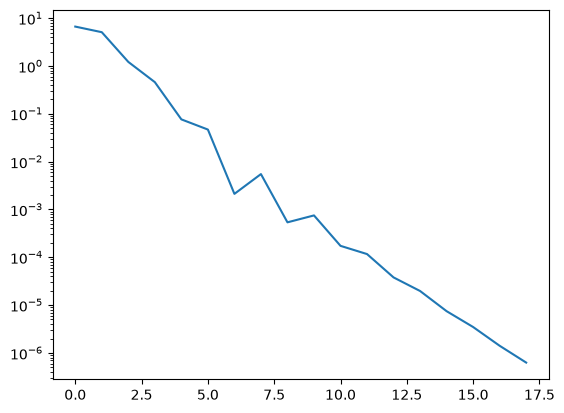

In [62]:
plt.semilogy(np.abs(error)) 

# VI Inverse Power iteration


What if we are interested in the smaller eigenvalue in magnitude?

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. What would be an eigenvalue of  ${\bf A}^{-1}$?


$${\bf A}^{-1}{\bf A}{\bf x}  = {\bf A}^{-1}\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \lambda {\bf A}^{-1} {\bf x}$$

$$\frac{1}{\lambda}{\bf x}  =  {\bf A}^{-1} {\bf x}$$


**Hence $\frac{1}{\lambda}$ is an eigenvalue of ${\bf A}^{-1} $**.

If we want to find the smallest eigenvalue in magnitude of ${\bf A}$, we can perform power iteration using the matrix ${\bf A}^{-1}$ to find $\bar\lambda = \frac{1}{\lambda}$, where  $\bar\lambda$ is the largest eigenvalue of ${\bf A}^{-1}$. (Power method with $A^{-1}$ will converge $|\frac{1}{\lambda _n}|$)

Let's implement that:

In [63]:
n = 4
D = np.diag([5,-1,2,7])

A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eig_index_sort
eigpos = eig_index_sort[0]

print(eigv[:,eigpos])

[ 0.32733003+0.j -0.06768667+0.j -0.92217218+0.j -0.19460737+0.j]


In [64]:
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm

for i in range(20):
    x = la.inv(A)@x
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x) 

lambdan =  -0.9999999999999077
un =  [-0.32733014  0.0676868   0.92217214  0.19460734]


Can you find ways to improve the code snippet above? 

In [65]:
#Inverse Power iteration to get smallest eigenvalue
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
P, L, Um = sla.lu(A)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  -0.9999999999976567
un =  [-0.32732949  0.06768602  0.92217239  0.19460751]


$x_{k+1} = A^{-1} x_k \Rightarrow A x_{k+1} = x_k$ solve for $x_{k+1}$
1) Factorize $A = PLU$ complexity: $O(n^3)$
2) solve for $Ly = b$ complexity: $O(n^2)$
3) solve for $Ux = y$ complexity: $O(n^2)$

# Inverse Shifted Power Iteration


What if we want to find another eigenvalue that is not the largest or the smallest? 

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. We want to find the eigenvalues of the shifted inverse matrix $({\bf A} - \sigma{\bf I})^{-1}$


$$({\bf A} - \sigma{\bf I})^{-1}{\bf x}  = \bar\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \bar\lambda ({\bf A} - \sigma{\bf I}) {\bf x} = \bar\lambda ({\lambda \bf I} - \sigma{\bf I}) {\bf x}$$

$$  \bar\lambda  = \frac{1}{\lambda-\sigma}$$


We could write the above eigenvalue problem as 


$$ {\bf B}^{-1}{\bf x}  = \bar\lambda {\bf x}$$

which can be solved by inverse power iteration, which will converge to the eigenvalue $\frac{1}{\lambda-\sigma}$

That is to say, we can use this method to find the eigenvalue that is closest to $\sigma$

In [66]:
n = 4
D = np.diag([5,-7,2,10])

A = U@D@U.T
eigl, eigv = la.eig(A)

print(eigl)
eigv

[-7.+0.j 10.+0.j  2.+0.j  5.+0.j]


array([[ 0.32733003+0.j, -0.39514411+0.j,  0.61185557+0.j,
         0.60195427+0.j],
       [-0.06768667+0.j, -0.24623144+0.j, -0.73768369+0.j,
         0.62498909+0.j],
       [-0.92217218+0.j, -0.29803976+0.j,  0.23812607+0.j,
         0.06377102+0.j],
       [-0.19460737+0.j,  0.83330877+0.j,  0.15732613+0.j,
         0.49292286+0.j]])

In [67]:
#Shifted Inverse Power iteration 
sigma = 1

x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
B = A - sigma*np.eye(n)
P, L, Um = sla.lu(B)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  2.0
un =  [ 0.61185557 -0.73768369  0.23812607  0.15732613]


# Computational cost and convergence


- power iteration: to obtain largest eigenvalue in magnitude ${\lambda_1}$
    - Matrix-vector multiplications at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_2}{\lambda_1} \right|$
    
   
- inverse power iteration: to obtain smallest eigenvalue in magnitude ${\lambda_n}$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_n}{\lambda_{n-1}} \right|$  
    
   
- inverse shifted power iteration: to obtain an eigenvalue close to a known/given value $\sigma$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_c - \sigma}{\lambda_{c2} - \sigma} \right|$  
    where $\lambda_c$ is the closest eigenvalue to $\sigma$ and $\lambda_{c2}$ is the second closest eigenvalue to $\sigma$.